<a href="https://colab.research.google.com/github/unwaveringfaith06/retinal_vessel_segmentation/blob/main/01_exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exploration de la base DRIVE

Objectif : examiner les photos du fond d’œil et leurs annotations
avant la préparation des données et l’entraînement de U-Net.

Vérifications :
- organisation des dossiers ;
- nombre et dimensions des images ;
- correspondance entre photos et annotations ;
- alignement visuel ;
- disponibilité des annotations du test.

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

PROJET = Path("/content/drive/MyDrive/MiniProjet-Rétinographie")
BASE = PROJET / "dataset" / "DRIVE"

if not BASE.is_dir():
    raise FileNotFoundError(f"Base introuvable : {BASE}")

print("Base accessible :", BASE)

Mounted at /content/drive
Base accessible : /content/drive/MyDrive/MiniProjet-Rétinographie/dataset/DRIVE


In [ ]:
EXTENSIONS = {
    ".png", ".jpg", ".jpeg", ".tif", ".tiff", ".gif", ".bmp"
}

def lister_images(dossier):
    return sorted(
        p for p in dossier.iterdir()
        if p.is_file() and p.suffix.lower() in EXTENSIONS
    )

for partie in ["training", "test"]:
    print(f"\n{partie.upper()}")

    for nom in ["images", "1st_manual", "mask"]:
        dossier = BASE / partie / nom

        if dossier.is_dir():
            print(f"  {nom} : {len(lister_images(dossier))} fichiers")
        else:
            print(f"  {nom} : absent")


TRAINING
  images : 20 fichiers
  1st_manual : 20 fichiers
  mask : 20 fichiers

TEST
  images : 20 fichiers
  1st_manual : absent
  mask : 20 fichiers


In [ ]:
def indexer(dossier):
    index = {}

    for chemin in lister_images(dossier):
        identifiant = chemin.stem.split("_")[0]

        if identifiant in index:
            raise ValueError(
                f"Identifiant en double : {identifiant} dans {dossier}"
            )

        index[identifiant] = chemin

    return index


photos = indexer(BASE / "training/images")
annotations = indexer(BASE / "training/1st_manual")
champs = indexer(BASE / "training/mask")

if not photos:
    raise ValueError("Aucune photo d'entraînement.")

if set(photos) != set(annotations):
    raise ValueError("Correspondances photo–annotation incomplètes.")

if set(photos) != set(champs):
    raise ValueError("Correspondances photo–champ rétinien incomplètes.")

paires = [
    (photos[i], annotations[i])
    for i in sorted(photos)
]

print("Correspondances vérifiées :", len(paires))

for photo, annotation in paires[:5]:
    print(photo.name, "↔", annotation.name)

Correspondances vérifiées : 20
21_training.tif ↔ 21_manual1.gif
22_training.tif ↔ 22_manual1.gif
23_training.tif ↔ 23_manual1.gif
24_training.tif ↔ 24_manual1.gif
25_training.tif ↔ 25_manual1.gif


In [ ]:
dimensions = set()
valeurs_annotations = set()

for photo, annotation in paires:
    identifiant = photo.stem.split("_")[0]

    with Image.open(photo) as fichier:
        taille_photo = fichier.size
        dimensions.add(taille_photo)

    with Image.open(annotation) as fichier:
        taille_annotation = fichier.size
        masque = np.asarray(fichier.convert("L"))
        valeurs_annotations.update(np.unique(masque).tolist())

    with Image.open(champs[identifiant]) as fichier:
        taille_champ = fichier.size

    if not (taille_photo == taille_annotation == taille_champ):
        raise ValueError(f"Dimensions incompatibles pour {photo.name}")

print("Dimensions des photos (largeur, hauteur) :", sorted(dimensions))
print("Valeurs présentes dans les annotations :", sorted(valeurs_annotations))
print("Toutes les photos sont alignées en dimensions avec leurs masques.")

Dimensions des photos (largeur, hauteur) : [(565, 584)]
Valeurs présentes dans les annotations : [0, 255]
Toutes les photos sont alignées en dimensions avec leurs masques.


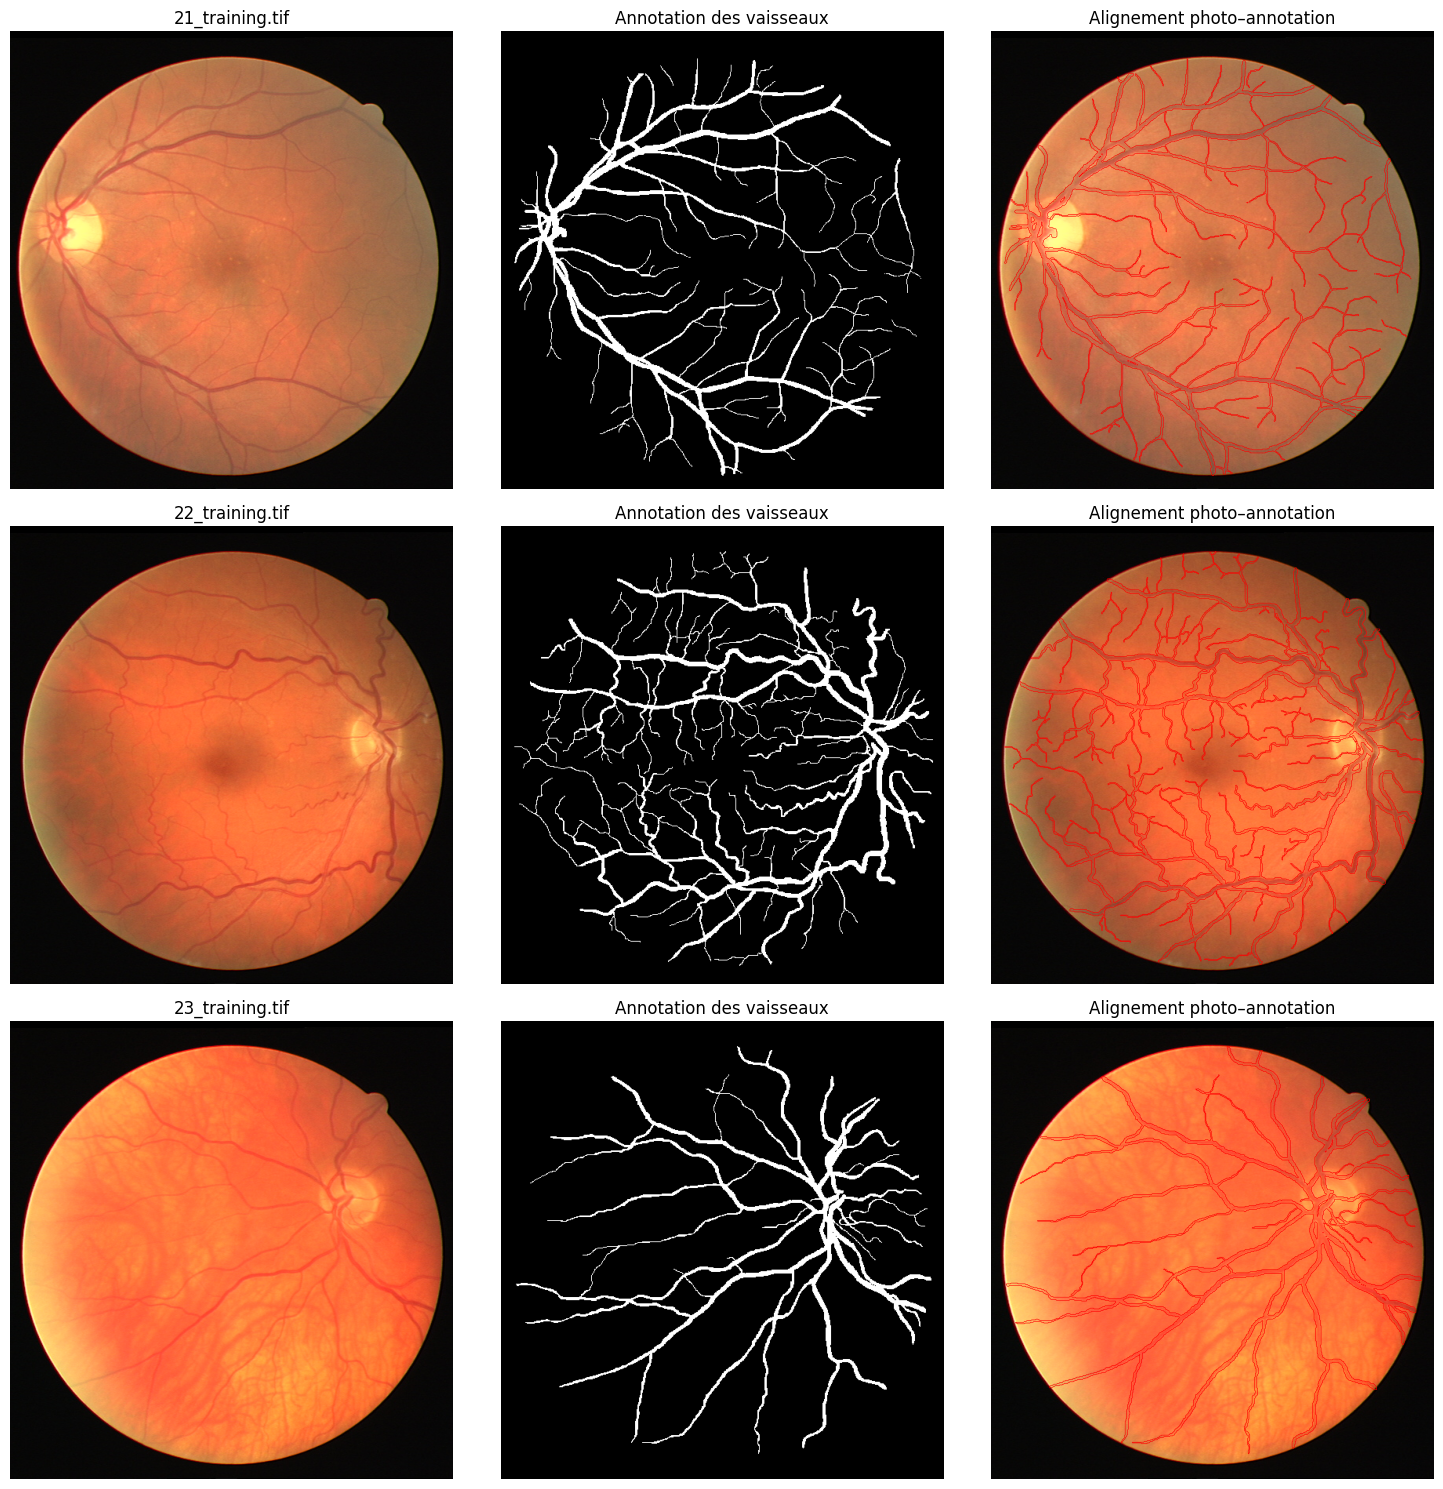

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(15, 15))

for ligne, (photo, annotation) in enumerate(paires[:3]):
    with Image.open(photo) as fichier:
        image = np.asarray(fichier.convert("RGB"))

    with Image.open(annotation) as fichier:
        masque = np.asarray(fichier.convert("L")) > 127

    axes[ligne, 0].imshow(image)
    axes[ligne, 0].set_title(photo.name)

    axes[ligne, 1].imshow(masque, cmap="gray")
    axes[ligne, 1].set_title("Annotation des vaisseaux")

    axes[ligne, 2].imshow(image)
    axes[ligne, 2].contour(
        masque,
        levels=[0.5],
        colors="red",
        linewidths=0.4
    )
    axes[ligne, 2].set_title("Alignement photo–annotation")

for ax in axes.ravel():
    ax.axis("off")

plt.tight_layout()
plt.show()

## Conclusion

La base comporte 20 photos d’entraînement avec annotations
manuelles des vaisseaux, et 20 photos de test.

Les annotations manuelles du test sont absentes de notre copie.
Les champs rétiniens sont disponibles pour les deux groupes.

La préparation sera réalisée dans 02_preprocessing.ipynb :
- séparation de 16 images d’entraînement et 4 de validation ;
- conservation des images 36, 30, 35 et 28 pour la validation ;
- redimensionnement en 512 × 512 ;
- normalisation des photos et binarisation des annotations ;
- sauvegarde des données préparées et de leur répartition.

Les images de test resteront séparées de l’apprentissage.